# Streaming Churn & Customer Retention Analytics

## 1. Introdução

Este projeto tem como objetivo analisar o cancelamento de assinaturas (churn) e os fatores relacionados à retenção de clientes em plataformas de streaming.

A análise utiliza uma base de dados sintética, criada com Python, contendo informações fictícias de 2.000 clientes.

## 2. Objetivos

- Investigar a taxa de cancelamento de assinaturas.
- Analisar a relação entre satisfação com o preço e cancelamento.
- Investigar a relação entre satisfação com o catálogo e cancelamento.
- Comparar o cancelamento entre clientes com e sem anúncios.
- Identificar os motivos de cancelamento e retenção registrados na base.

## 3. Ferramentas utilizadas

- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook

## 4. Observação sobre os dados

Os dados utilizados são inteiramente sintéticos e não representam clientes reais de nenhuma plataforma. Os padrões encontrados servem para fins educacionais e não devem ser interpretados como conclusões sobre o mercado real de streaming.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Carregar a base de dados
df = pd.read_csv("../data/streaming_customers.csv")

# Exibir as primeiras 5 linhas
df.head()

,customer_id,platform,months_subscribed,price_satisfaction,content_satisfaction,ad_tolerance,plan_type,has_ads,ad_satisfaction,ad_free_upgrade_interest,subscription_status,cancellation_reason,retention_reason
0,C0001,Disney+,47,1,5,3,Padrão,False,NaN,Não se aplica,Ativo,Não se aplica,Uso compartilhado
1,C0002,HBO Max,12,3,1,2,Premium,False,NaN,Não se aplica,Cancelado,Insatisfação com o catálogo,Não se aplica
2,C0003,Netflix,16,5,2,4,Padrão,False,NaN,Não se aplica,Ativo,Não se aplica,Uso compartilhado
3,C0004,Disney+,24,1,2,2,Básico com anúncios,True,5.0,Não,Cancelado,Pouco uso da plataforma,Não se aplica
4,C0005,Disney+,19,4,1,5,Premium,False,NaN,Não se aplica,Cancelado,Pouco uso da plataforma,Não se aplica


In [2]:
# Verificar a quantidade de linhas e colunas
print("Formato da base:", df.shape)

# Conferir os nomes das colunas
print("\nColunas disponíveis:")
print(df.columns.tolist())

# Verificar os tipos de dados
print("\nTipos de dados:")
df.info()

Formato da base: (2000, 13)

Colunas disponíveis:
['customer_id', 'platform', 'months_subscribed', 'price_satisfaction', 'content_satisfaction', 'ad_tolerance', 'plan_type', 'has_ads', 'ad_satisfaction', 'ad_free_upgrade_interest', 'subscription_status', 'cancellation_reason', 'retention_reason']

Tipos de dados:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               2000 non-null   str    
 1   platform                  2000 non-null   str    
 2   months_subscribed         2000 non-null   int64  
 3   price_satisfaction        2000 non-null   int64  
 4   content_satisfaction      2000 non-null   int64  
 5   ad_tolerance              2000 non-null   int64  
 6   plan_type                 2000 non-null   str    
 7   has_ads                   2000 non-null   bool   
 8   ad_satisfaction           771 non-

In [3]:
# Contar valores ausentes em cada coluna
print("Valores ausentes por coluna:")
print(df.isnull().sum())

# Comparar a presença de anúncios com a satisfação sobre anúncios
print("\nClientes com e sem anúncios:")
print(df.groupby("has_ads")["ad_satisfaction"].agg(
    total="count"
))

# Conferir a quantidade de clientes em cada grupo
print("\nQuantidade de clientes por grupo:")
print(df["has_ads"].value_counts())

Valores ausentes por coluna:
customer_id                    0
platform                       0
months_subscribed              0
price_satisfaction             0
content_satisfaction           0
ad_tolerance                   0
plan_type                      0
has_ads                        0
ad_satisfaction             1229
ad_free_upgrade_interest       0
subscription_status            0
cancellation_reason            0
retention_reason               0
dtype: int64

Clientes com e sem anúncios:
         total
has_ads       
False        0
True       771

Quantidade de clientes por grupo:
has_ads
False    1229
True      771
Name: count, dtype: int64


In [4]:
# Contar clientes por situação da assinatura
print("Situação das assinaturas:")
print(df["subscription_status"].value_counts())

# Calcular a proporção de cancelamentos
taxa_cancelamento = (
    df["subscription_status"].eq("Canceled").mean() * 100
)

print(f"\nTaxa de cancelamento: {taxa_cancelamento:.2f}%")

Situação das assinaturas:
subscription_status
Ativo        1122
Cancelado     878
Name: count, dtype: int64

Taxa de cancelamento: 0.00%


In [5]:
# Contar cada situação da assinatura
print(df["subscription_status"].value_counts())

# Calcular a taxa de cancelamento
taxa_cancelamento = (
    df["subscription_status"].eq("Cancelado").mean() * 100
)

print(f"\nTaxa de cancelamento: {taxa_cancelamento:.2f}%")

subscription_status
Ativo        1122
Cancelado     878
Name: count, dtype: int64

Taxa de cancelamento: 43.90%


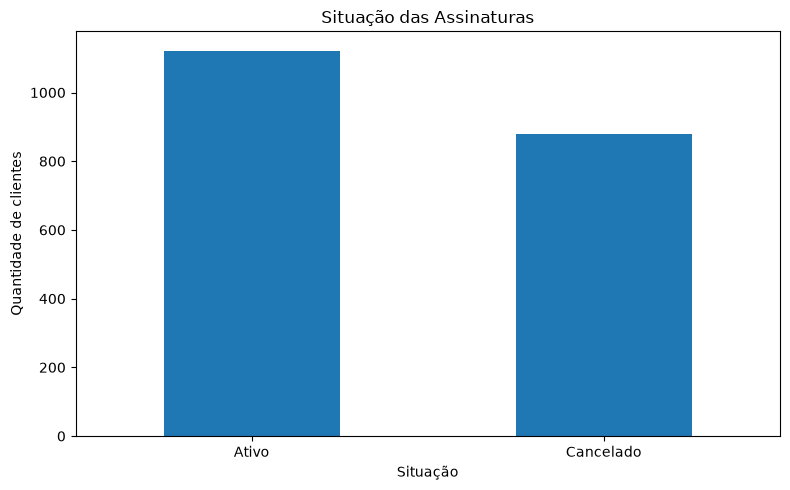

In [6]:
# Contar clientes por situação da assinatura
situacao = df["subscription_status"].value_counts()

# Criar o gráfico
plt.figure(figsize=(8, 5))
situacao.plot(kind="bar")

plt.title("Situação das Assinaturas")
plt.xlabel("Situação")
plt.ylabel("Quantidade de clientes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Taxa de cancelamento por presença de anúncios:
Sem anúncios    42.55
Com anúncios    46.04
Name: subscription_status, dtype: float64


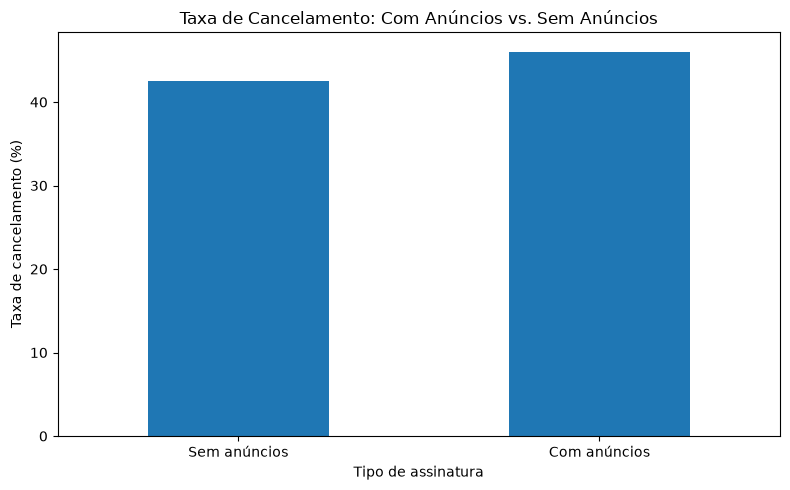

In [7]:
# Calcular a taxa de cancelamento por presença de anúncios
taxa_por_anuncios = (
    df.groupby("has_ads")["subscription_status"]
    .apply(lambda grupo: grupo.eq("Cancelado").mean() * 100)
)

# Deixar os nomes mais fáceis de entender
taxa_por_anuncios.index = [
    "Sem anúncios" if valor is False else "Com anúncios"
    for valor in taxa_por_anuncios.index
]

print("Taxa de cancelamento por presença de anúncios:")
print(taxa_por_anuncios.round(2))

# Criar o gráfico
plt.figure(figsize=(8, 5))
taxa_por_anuncios.plot(kind="bar")

plt.title("Taxa de Cancelamento: Com Anúncios vs. Sem Anúncios")
plt.xlabel("Tipo de assinatura")
plt.ylabel("Taxa de cancelamento (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Análise da taxa de cancelamento por presença de anúncios

A comparação entre os grupos permite observar se as taxas de cancelamento diferem entre clientes com e sem anúncios.

Como a base de dados é sintética, os resultados representam padrões artificiais utilizados para fins educacionais. A diferença observada não permite concluir que os anúncios causam cancelamentos no mercado real.

print("Taxa de cancelamento por grupo:")

for grupo, taxa in taxa_por_anuncios.items():
    print(f"{grupo}: {taxa:.2f}%")

diferenca = (
    taxa_por_anuncios["Com anúncios"]
    - taxa_por_anuncios["Sem anúncios"]
)

print(f"\nDiferença entre os grupos: {diferenca:.2f} pontos percentuais")

In [8]:
print("Teste de execução funcionando!")

Teste de execução funcionando!


In [9]:
taxa_por_anuncios

Sem anúncios    42.554923
Com anúncios    46.044099
Name: subscription_status, dtype: float64

### Interpretação dos resultados

A taxa de cancelamento foi de 46,04% entre os clientes com anúncios e de 42,55% entre os clientes sem anúncios.

A diferença observada foi de aproximadamente 3,49 pontos percentuais. Nesta base sintética, o grupo com anúncios apresentou uma taxa de cancelamento maior.

Entretanto, essa comparação é descritiva e não demonstra uma relação de causa e efeito. Como os dados são fictícios, os resultados servem para praticar análise exploratória e não representam o comportamento real de consumidores de streaming.

Taxa de cancelamento por satisfação com o preço:
price_satisfaction
1    53.20
2    51.18
3    37.74
4    40.72
5    37.16
Name: subscription_status, dtype: float64


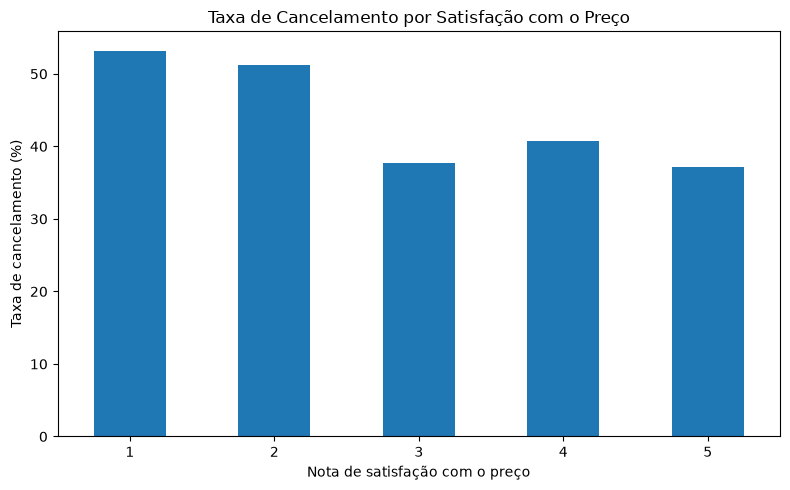

In [10]:
# Calcular a taxa de cancelamento por satisfação com o preço
taxa_por_preco = (
    df.groupby("price_satisfaction")["subscription_status"]
    .apply(lambda grupo: grupo.eq("Cancelado").mean() * 100)
)

print("Taxa de cancelamento por satisfação com o preço:")
print(taxa_por_preco.round(2))

# Criar o gráfico
plt.figure(figsize=(8, 5))
taxa_por_preco.plot(kind="bar")

plt.title("Taxa de Cancelamento por Satisfação com o Preço")
plt.xlabel("Nota de satisfação com o preço")
plt.ylabel("Taxa de cancelamento (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
print("Taxa de cancelamento por nota de satisfação:")

for nota, taxa in taxa_por_preco.items():
    print(f"Nota {nota}: {taxa:.2f}%")

Taxa de cancelamento por nota de satisfação:
Nota 1: 53.20%
Nota 2: 51.18%
Nota 3: 37.74%
Nota 4: 40.72%
Nota 5: 37.16%


### Interpretação: satisfação com o preço

A nota 1 apresentou a maior taxa de cancelamento (53,20%), seguida pela nota 2 (51,18%). A menor taxa foi observada na nota 5, com 37,16%.

Os resultados sugerem uma associação entre menor satisfação com o preço e maior taxa de cancelamento nesta base sintética. Entretanto, a tendência não é perfeitamente contínua, pois a nota 4 apresentou uma taxa de cancelamento superior à nota 3.

Como os dados são fictícios, essa análise é um exercício de exploração de dados e não comprova uma relação causal no mercado real.

Taxa de cancelamento por satisfação com o conteúdo:
Nota 1: 51.19%
Nota 2: 52.21%
Nota 3: 39.15%
Nota 4: 39.66%
Nota 5: 36.97%


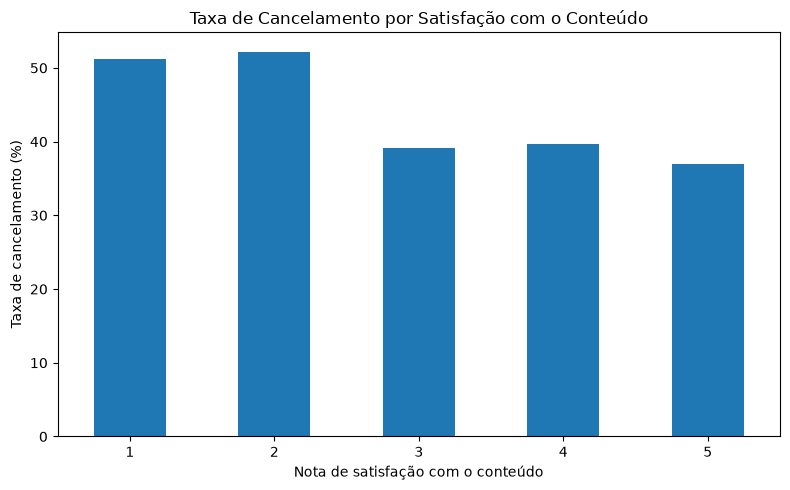

In [12]:
# Calcular a taxa de cancelamento por satisfação com o conteúdo
taxa_por_conteudo = (
    df.groupby("content_satisfaction")["subscription_status"]
    .apply(lambda grupo: grupo.eq("Cancelado").mean() * 100)
)

# Mostrar os percentuais
print("Taxa de cancelamento por satisfação com o conteúdo:")

for nota, taxa in taxa_por_conteudo.items():
    print(f"Nota {nota}: {taxa:.2f}%")

# Criar o gráfico
plt.figure(figsize=(8, 5))
taxa_por_conteudo.plot(kind="bar")

plt.title("Taxa de Cancelamento por Satisfação com o Conteúdo")
plt.xlabel("Nota de satisfação com o conteúdo")
plt.ylabel("Taxa de cancelamento (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
print("Taxa de cancelamento por nota de satisfação com o conteúdo:")

for nota, taxa in taxa_por_conteudo.items():
    print(f"Nota {nota}: {taxa:.2f}%")

Taxa de cancelamento por nota de satisfação com o conteúdo:
Nota 1: 51.19%
Nota 2: 52.21%
Nota 3: 39.15%
Nota 4: 39.66%
Nota 5: 36.97%


### Interpretação: satisfação com o conteúdo

A nota 2 apresentou a maior taxa de cancelamento (52,21%), seguida pela nota 1 (51,19%). Já a nota 5 apresentou a menor taxa, com 36,97%.

Os resultados sugerem uma associação entre menor satisfação com o catálogo de conteúdo e maior taxa de cancelamento nesta base sintética. As notas 3 e 4 apresentaram taxas semelhantes, sem uma redução contínua em todos os níveis.

Como os dados são fictícios, os resultados servem para praticar análise exploratória e não comprovam uma relação causal no mercado real de streaming.

Motivos de cancelamento:
cancellation_reason
Preço alto                     240
Pouco uso da plataforma        217
Excesso de anúncios            213
Insatisfação com o catálogo    208
Name: count, dtype: int64


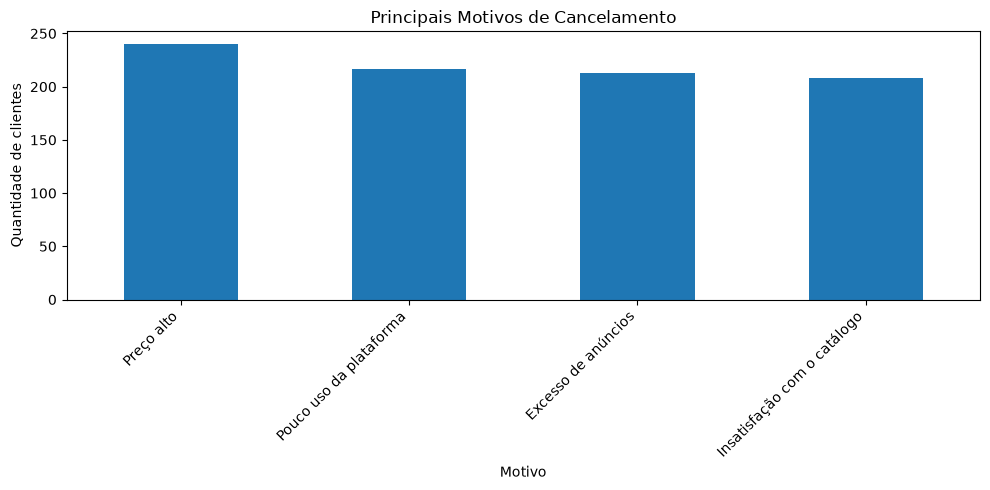

In [14]:
# Selecionar apenas os clientes que cancelaram
clientes_cancelados = df[
    df["subscription_status"] == "Cancelado"
]

# Contar os motivos de cancelamento
motivos_cancelamento = (
    clientes_cancelados["cancellation_reason"]
    .value_counts()
)

print("Motivos de cancelamento:")
print(motivos_cancelamento)

# Gerar gráfico
plt.figure(figsize=(10, 5))
motivos_cancelamento.plot(kind="bar")

plt.title("Principais Motivos de Cancelamento")
plt.xlabel("Motivo")
plt.ylabel("Quantidade de clientes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [15]:
print("Quantidade de cancelamentos por motivo:\n")

for motivo, quantidade in motivos_cancelamento.items():
    print(f"{motivo}: {quantidade} clientes")

Quantidade de cancelamentos por motivo:

Preço alto: 240 clientes
Pouco uso da plataforma: 217 clientes
Excesso de anúncios: 213 clientes
Insatisfação com o catálogo: 208 clientes


### Interpretação: motivos de cancelamento

O preço alto foi o motivo de cancelamento mais frequente, informado por 240 clientes. Em seguida, aparecem pouco uso da plataforma, com 217 clientes, excesso de anúncios, com 213, e insatisfação com o catálogo, com 208.

Embora o preço tenha sido o motivo mais frequente, a diferença entre as quatro categorias foi relativamente pequena. Isso indica que, nesta base sintética, diferentes aspectos da experiência de assinatura merecem atenção.

Como os dados são fictícios, esses resultados não representam necessariamente o comportamento de consumidores reais de streaming.

Motivos de retenção:
retention_reason
Catálogo de conteúdo       301
Uso compartilhado          285
Tolerância aos anúncios    276
Preço acessível            260
Name: count, dtype: int64


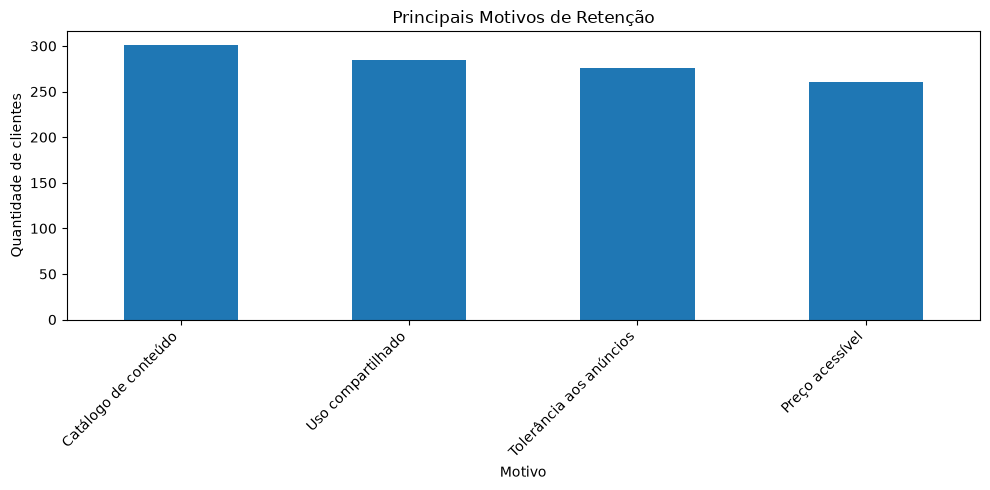

In [16]:
# Selecionar apenas os clientes com assinatura ativa
clientes_ativos = df[
    df["subscription_status"] == "Ativo"
]

# Contar os motivos de retenção
motivos_retencao = (
    clientes_ativos["retention_reason"]
    .value_counts()
)

print("Motivos de retenção:")
print(motivos_retencao)

# Gerar gráfico
plt.figure(figsize=(10, 5))
motivos_retencao.plot(kind="bar")

plt.title("Principais Motivos de Retenção")
plt.xlabel("Motivo")
plt.ylabel("Quantidade de clientes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [17]:
print("Quantidade de clientes por motivo de retenção:\n")

for motivo, quantidade in motivos_retencao.items():
    print(f"{motivo}: {quantidade} clientes")

Quantidade de clientes por motivo de retenção:

Catálogo de conteúdo: 301 clientes
Uso compartilhado: 285 clientes
Tolerância aos anúncios: 276 clientes
Preço acessível: 260 clientes


### Interpretação: motivos de retenção

O catálogo de conteúdo foi o motivo de retenção mais frequente, citado por 301 clientes ativos. Em seguida, aparecem uso compartilhado, com 285 clientes, tolerância aos anúncios, com 276, e preço acessível, com 260.

Os resultados mostram que o catálogo de conteúdo foi a categoria mais frequente entre os motivos registrados. Entretanto, as diferenças entre as quatro categorias são relativamente pequenas.

Como os dados são sintéticos, esses resultados são utilizados para fins educacionais e não representam necessariamente o comportamento de consumidores reais. Além disso, a análise identifica frequências, mas não comprova que esses fatores sejam a causa da permanência dos clientes.